# 20. Metamaterial Slab Waveguide Dispersion via S-Matrix Poles

## Physical Motivation & Learning Objectives
Guided modes in a dielectric or metamaterial slab correspond to non-trivial solutions without incident illumination, which manifest as **poles of the round-trip scattering matrix**:
$$\det(I - R_{21} P R_{21} P) = 0$$
Based on [Lemoult et al., Nature Physics 9, 55 (2013)] and [Sturmberg et al., Phys. Rev. B 91, 165430 (2015)](https://doi.org/10.1103/PhysRevB.91.165430), EMUstack locates guided modes via `plotting.Fabry_Perot_res`.



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.


 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.


 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.


 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.


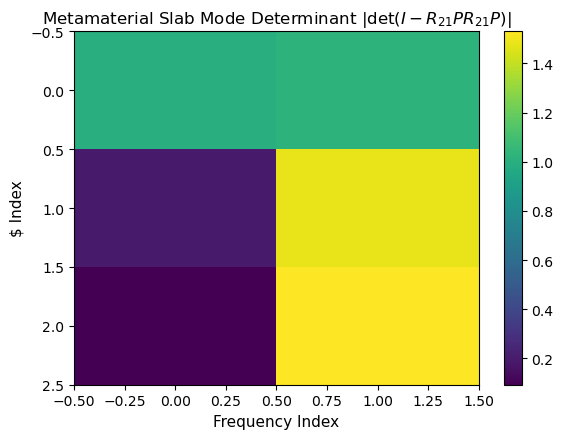

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

c_speed = 299792458
wl_0 = 0.8e9
f_0 = c_speed / wl_0
k_0 = 2 * np.pi / wl_0
omega_0 = 2 * np.pi * f_0

min_freq = 0.712 * f_0
max_freq = 1.0 * f_0
n_freqs = 2
min_kx = 0.6 * k_0
max_kx = 30 * k_0
n_kxs = 3

freq_list = np.linspace(max_freq, min_freq, n_freqs)
wl_list = (c_speed / freq_list)
kx_list = np.linspace(min_kx, max_kx, n_kxs)

period = 0.012e9
n = 1.0
NW_rads = 0.0015e9
NW_diameter = NW_rads * 2

strate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
NW_array = objects.NanoStruct(
    '2D_array', period, NW_diameter, height_nm=wl_0 / (2 * n),
    inclusion_a=materials.Material(0.0 + 1e6j), background=materials.Material(n),
    loss=True, hyperbolic=True, make_mesh_now=True, force_mesh=False, lc_bkg=0.1, lc2=4.0
)

def simulate_stack(lyte):
    wl, kx = lyte[0], lyte[1]
    light = objects.Light(wl, max_order_PWs=2, k_parallel=[kx, 1e-12])
    sim_NWs = NW_array.calc_modes(light, num_BMs=30)
    sim_strate = strate.calc_modes(light)
    stk = Stack((sim_strate, sim_NWs, sim_strate))
    stk.calc_scat(pol='TE')
    num_BMs = sim_NWs.num_BMs
    I_mat = np.matrix(np.eye(num_BMs), dtype='D')
    height = stk.heights_nm()[0]
    P = stk.layers[1].prop_fwd(height / period)
    R21 = stk.layers[1].R21
    det = np.linalg.det(I_mat - R21 * P * R21 * P)
    return np.exp(1j) * det

light_list = []
for kx in kx_list:
    for wl in wl_list:
        light_list.append((wl, kx))

stacks_list = [simulate_stack(item) for item in light_list]
stacks_mat = np.array(stacks_list).reshape(len(kx_list), len(wl_list))

fig, ax = plt.subplots(figsize=(6, 4.5), dpi=100)
im = ax.imshow(np.abs(stacks_mat), cmap='viridis', aspect='auto')
ax.set_xlabel('Frequency Index', fontsize=11)
ax.set_ylabel(r'$ Index', fontsize=11)
ax.set_title(r'Metamaterial Slab Mode Determinant $|\det(I - R_{21} P R_{21} P)|$', fontsize=12)
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


## Slab Resonator Setup & S-Matrix Pole Search


## Fabry-Perot Resonance Determinant


## Physical Interpretation
Minima of $\det(I - R_{21} P R_{21} P)$ pinpoint the guided waveguide mode frequencies where the phase-matching condition for total internal reflection is satisfied.
